<a href="https://colab.research.google.com/github/Raj-18-45/Machine-Learning/blob/main/Data%20Preprocessing/Using%20titatnic%20dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Data Preprocessing**

Objective

To preprocess datasets by handling missing values, encoding categorical variables, and scaling numerical features to prepare the data for machine learning.

About the Datasets

This experiment uses two datasets:

1. Titanic Dataset
Contains passenger information such as age, sex, passenger class, fare, number of siblings or spouses, number of parents or children, and port of embarkation. The dataset also includes survival information.

In [1]:
#Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [6]:
#Load and Explore the Dataset
df = pd.read_csv('/content/Titanic-Dataset.csv')
print(df.head())
print(df.shape)
df.info()
print(df.isnull().sum())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
(8

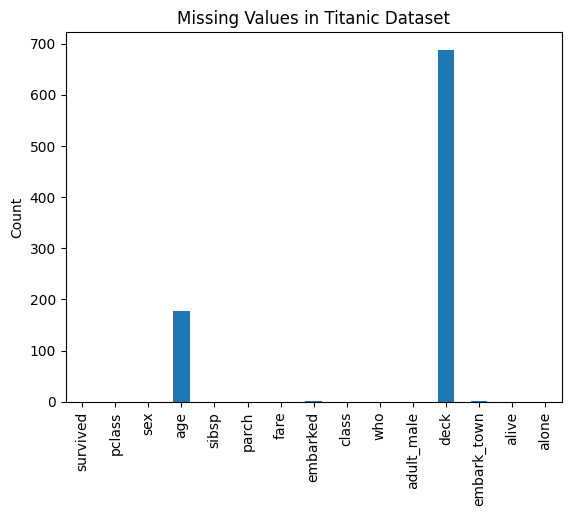

In [3]:
#: Visualize Missing Values
df.isnull().sum().plot(kind='bar')

plt.title("Missing Values in Titanic Dataset")

plt.ylabel("Count")

plt.show()

In [8]:
#Handle Missing Values
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

df['Has_Cabin'] = df['Cabin'].notnull().astype(int)

df.drop(columns=['Name', 'Ticket', 'Cabin'], inplace=True)

print(df.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Sex            0
Age            0
SibSp          0
Parch          0
Fare           0
Embarked       0
Has_Cabin      0
dtype: int64


In [10]:
#Encode Categorical Variables
le = LabelEncoder()

df['Sex'] = le.fit_transform(df['Sex'])
df['Embarked'] = le.fit_transform(df['Embarked'])

In [11]:
#Scale Numerical Features
cols = ['Age', 'Fare', 'SibSp', 'Parch']

scaler = StandardScaler()

df[cols] = scaler.fit_transform(df[cols])

print(df.head())

   PassengerId  Survived  Pclass  Sex       Age     SibSp     Parch      Fare  \
0            1         0       3    1 -0.565736  0.432793 -0.473674 -0.502445   
1            2         1       1    0  0.663861  0.432793 -0.473674  0.786845   
2            3         1       3    0 -0.258337 -0.474545 -0.473674 -0.488854   
3            4         1       1    0  0.433312  0.432793 -0.473674  0.420730   
4            5         0       3    1  0.433312 -0.474545 -0.473674 -0.486337   

   Embarked  Has_Cabin  
0         2          0  
1         0          1  
2         2          0  
3         2          1  
4         2          0  


In [12]:
print("Final Shape:", df.shape)

print("Missing Values:\n", df.isnull().sum())

print(df.head())

Final Shape: (891, 10)
Missing Values:
 PassengerId    0
Survived       0
Pclass         0
Sex            0
Age            0
SibSp          0
Parch          0
Fare           0
Embarked       0
Has_Cabin      0
dtype: int64
   PassengerId  Survived  Pclass  Sex       Age     SibSp     Parch      Fare  \
0            1         0       3    1 -0.565736  0.432793 -0.473674 -0.502445   
1            2         1       1    0  0.663861  0.432793 -0.473674  0.786845   
2            3         1       3    0 -0.258337 -0.474545 -0.473674 -0.488854   
3            4         1       1    0  0.433312  0.432793 -0.473674  0.420730   
4            5         0       3    1  0.433312 -0.474545 -0.473674 -0.486337   

   Embarked  Has_Cabin  
0         2          0  
1         0          1  
2         2          0  
3         2          1  
4         2          0  
